# 03: Data Preprocessing (Anggota 3)

Penjelasan dan bukti hasil `src/03_preprocessing.py`: data mentah Zenodo dan BPS jadi data bersih di `data/clean/`.

In [1]:
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, CLEAN = ROOT / "data" / "raw", ROOT / "data" / "clean"
FIG = ROOT / "outputs" / "preprocessing"
FIG.mkdir(parents=True, exist_ok=True)

spec = importlib.util.spec_from_file_location("pre", ROOT / "src" / "03_preprocessing.py")
pre = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pre)

RUN_PIPELINE = False
if RUN_PIPELINE or not (CLEAN / "dim_kapanewon.parquet").exists():
    pre.run_all()

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_columns", 30, "display.width", 160)
print("ROOT:", ROOT)

ROOT: D:\Program Files\JogjaPulse


## 1. Gambaran semua file bersih

In [2]:
rows = []
for p in sorted(CLEAN.glob("*.parquet")):
    d = pd.read_parquet(p)
    rows.append({"file": p.stem, "baris": len(d), "kolom": d.shape[1],
                 "ada_csv": (CLEAN / f"{p.stem}.csv").exists()})
inventory = pd.DataFrame(rows)
inventory

,file,baris,kolom,ada_csv
0,bps_population_kapanewon_diy_2021_2022,156,10,True
1,coverage_kapanewon_hourly,11451,6,True
2,dim_kapanewon,78,4,True
3,home_maids_vs_population_kapanewon,78,8,True
4,od_home_visits_kapanewon_monthly,9894,14,True
5,od_origin_homes_monthly,390,8,True
6,od_summary,1,7,True
7,presence_cell500m_daily,183548,13,False
8,presence_kapanewon_hourly,230418,16,False
9,tier1_summary,2,8,True


Tabel di bawah 20.000 baris disimpan juga sebagai CSV, tabel besar hanya Parquet.

### Sebelum dan sesudah (contoh: `presence_kapanewon_hourly`)

In [3]:
raw = pd.read_csv(RAW / "zenodo" / "presence_kapanewon_hourly.csv")
clean = pd.read_parquet(CLEAN / "presence_kapanewon_hourly.parquet")
cmp = pd.DataFrame({"mentah": raw.dtypes.astype(str)}).join(
      pd.DataFrame({"bersih": clean.dtypes.astype(str)}), how="outer")
cmp["kolom_baru"] = cmp["mentah"].isna()
cmp

,mentah,bersih,kolom_baru
date,object,datetime64[ns],False
datetime,NaN,datetime64[ns],True
dayofweek,NaN,int8,True
hour,int64,int8,False
is_anomaly_day,NaN,bool,True
is_weekend,NaN,bool,True
kab_code,float64,object,False
kab_kota,object,string,False
kapanewon,object,string,False
kapanewon_code,object,object,False


Kode wilayah dibaca sebagai teks, karena kalau dibaca sebagai angka `34.10` bisa jadi `34.1`. Tanggal diubah ke `datetime` dan kolom angka dikecilkan tipenya.

In [4]:
clean.head()

,kapanewon_code,kab_code,kab_kota,kapanewon,datetime,date,hour,dayofweek,is_weekend,month,n_maids,n_pings,pings_per_maid,share_in_hour,supply_regime,is_anomaly_day
0,34.01.01,34.01,KULON PROGO,TEMON,2021-12-01 00:00:00,2021-12-01,0,2,False,2021-12,16,66,4.125000,0.004207,A,False
1,34.01.01,34.01,KULON PROGO,TEMON,2021-12-01 01:00:00,2021-12-01,1,2,False,2021-12,8,38,4.750000,0.002566,A,False
2,34.01.01,34.01,KULON PROGO,TEMON,2021-12-01 02:00:00,2021-12-01,2,2,False,2021-12,7,19,2.714286,0.003755,A,False
3,34.01.01,34.01,KULON PROGO,TEMON,2021-12-01 03:00:00,2021-12-01,3,2,False,2021-12,9,22,2.444444,0.005952,A,False
4,34.01.01,34.01,KULON PROGO,TEMON,2021-12-01 04:00:00,2021-12-01,4,2,False,2021-12,17,34,2.000000,0.009737,A,False


## 2. Standarisasi nama wilayah
Awalan `KEC.`/`KAB.`, huruf kecil, dan spasi ganda diseragamkan. Kata `KOTA` hanya dibuang dari nama kabupaten, bukan dari kapanewon (`KOTAGEDE` tetap).

In [5]:
contoh_kab = pd.Series(["KAB. Sleman", "Kabupaten  Bantul", "KOTA YOGYAKARTA", "gunungkidul ", "KULON PROGO"])
contoh_kec = pd.Series(["KEC. Banguntapan", "Kapanewon  Jetis ", "KEMANTREN Gondomanan", "KOTAGEDE", "Gamping"])
pd.DataFrame({"kab_asli": contoh_kab, "kab_baku": pre.normalize_kab(contoh_kab),
              "kec_asli": contoh_kec, "kec_baku": pre.normalize_kec(contoh_kec)})

,kab_asli,kab_baku,kec_asli,kec_baku
0,KAB. Sleman,SLEMAN,KEC. Banguntapan,BANGUNTAPAN
1,Kabupaten Bantul,BANTUL,Kapanewon Jetis,JETIS
2,KOTA YOGYAKARTA,YOGYAKARTA,KEMANTREN Gondomanan,GONDOMANAN
3,gunungkidul,GUNUNGKIDUL,KOTAGEDE,KOTAGEDE
4,KULON PROGO,KULON PROGO,Gamping,GAMPING


## 3. Kunci join: `kapanewon_code`
Nama JETIS ada dua, jadi join pakai nama saja menggandakan baris.

In [6]:
dim = pd.read_parquet(CLEAN / "dim_kapanewon.parquet")
print("kapanewon:", len(dim), "| nama unik:", dim["kapanewon"].nunique())
dim[dim["kapanewon"].duplicated(keep=False)]

kapanewon: 78 | nama unik: 77


,kapanewon_code,kab_kota,kapanewon,kab_code
20,34.02.09,BANTUL,JETIS,34.02
65,34.71.02,YOGYAKARTA,JETIS,34.71


In [7]:
home = pd.read_parquet(CLEAN / "home_maids_vs_population_kapanewon.parquet")
# join SALAH: hanya nama
salah = home[["kapanewon", "n_users"]].merge(dim[["kapanewon", "kapanewon_code"]], on="kapanewon")
# join BENAR: kode
benar = home[["kapanewon_code", "n_users"]].merge(dim[["kapanewon_code", "kab_kota"]], on="kapanewon_code")
pd.DataFrame({"metode": ["join nama saja", "join kapanewon_code"],
              "baris_hasil": [len(salah), len(benar)], "baris_seharusnya": [78, 78]})

,metode,baris_hasil,baris_seharusnya
0,join nama saja,80,78
1,join kapanewon_code,78,78


Join nama saja menghasilkan 80 baris, join kode tetap 78. Karena itu `kapanewon_code` ditambahkan ke semua tabel (lewat `(kab_kota, kapanewon)` untuk file yang tidak punya kode).

## 4. Baris yang hilang bukan nol
Slot dengan kurang dari 5 device tidak diterbitkan (k-anonymity). Slot kosong bukan 0, jadi tidak diisi.

In [8]:
n_days = clean["date"].nunique()
cov = (clean.groupby(["kapanewon_code", "kapanewon", "kab_kota"]).size().rename("slot_terbit").reset_index())
cov["pct_terbit"] = cov["slot_terbit"] / (n_days * 24)
print(f"Slot terbit keseluruhan: {len(clean):,} dari {78 * n_days * 24:,} ({len(clean) / (78 * n_days * 24):.1%})")
cov.sort_values("pct_terbit").head(10)

Slot terbit keseluruhan: 230,418 dari 282,672 (81.5%)


,kapanewon_code,kapanewon,kab_kota,slot_terbit,pct_terbit
44,34.03.16,GIRISUBO,GUNUNGKIDUL,784,0.216336
39,34.03.11,RONGKOP,GUNUNGKIDUL,1000,0.275938
46,34.03.18,PURWOSARI,GUNUNGKIDUL,1284,0.354305
35,34.03.07,TEPUS,GUNUNGKIDUL,1529,0.421909
45,34.03.17,TANJUNGSARI,GUNUNGKIDUL,1591,0.439018
43,34.03.15,SAPTOSARI,GUNUNGKIDUL,1646,0.454194
34,34.03.06,PANGGANG,GUNUNGKIDUL,1806,0.498344
41,34.03.13,NGAWEN,GUNUNGKIDUL,1924,0.530905
2,34.01.03,PANJATAN,KULON PROGO,2299,0.634382
33,34.03.05,PALIYAN,GUNUNGKIDUL,2307,0.636589


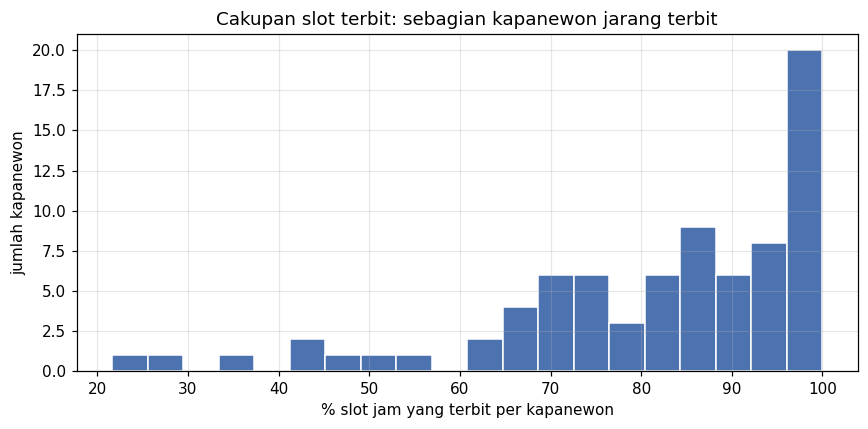

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cov["pct_terbit"] * 100, bins=20, color="#4C72B0", edgecolor="white")
ax.set_xlabel("% slot jam yang terbit per kapanewon"); ax.set_ylabel("jumlah kapanewon")
ax.set_title("Cakupan slot terbit: sebagian kapanewon jarang terbit")
fig.tight_layout(); fig.savefig(FIG / "01_cakupan_slot_terbit.png"); plt.show()

Cakupan terendah ada di Gunungkidul (Girisubo ±22%, Rongkop ±28%), sedangkan Sleman dan Kota Yogyakarta median ±93-98%. Wilayah yang jarang terbit bisa tampak lebih sepi hanya karena disensor.

## 5. Perubahan jumlah device (`supply_regime`)
Jumlah device di data turun pada 1 Jan dan 16 Feb 2022, dan 8 Mar 2022 anomali. Median `n_maids` per slot: ±60 (A), ±50 (B), ±14 (C). Ini perubahan sampel data, bukan perilaku orang, jadi ditambah `supply_regime` (A < 1 Jan, B 1 Jan-15 Feb, C mulai 16 Feb) dan `is_anomaly_day` (8 Mar).

`n_maids` tidak boleh dijumlahkan antar wilayah (device unik), jadi grafik memakai median per slot dan jumlah slot terbit.

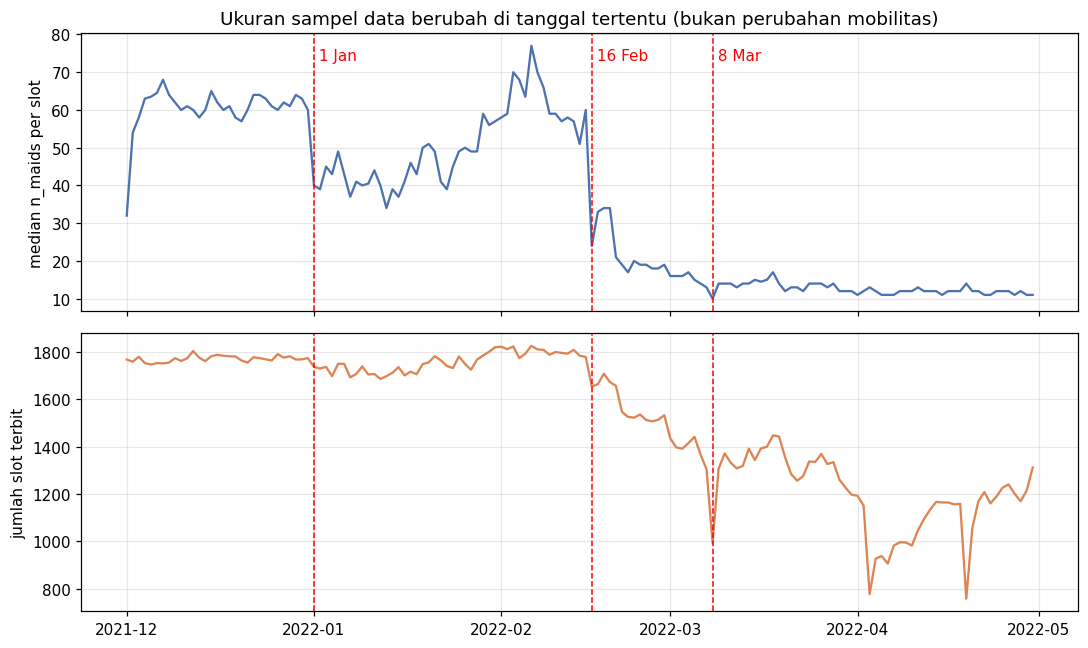

In [10]:
daily = clean.groupby("date").agg(median_n_maids=("n_maids", "median"), slot_terbit=("n_maids", "size")).reset_index()
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily["date"], daily["median_n_maids"], color="#4C72B0")
axes[0].set_ylabel("median n_maids per slot")
axes[1].plot(daily["date"], daily["slot_terbit"], color="#DD8452")
axes[1].set_ylabel("jumlah slot terbit")
for ax in axes:
    for d, lab in [(pre.BREAK_1, "1 Jan"), (pre.BREAK_2, "16 Feb"), (pre.ANOMALY_DAYS[0], "8 Mar")]:
        ax.axvline(d, color="red", ls="--", lw=1)
axes[0].text(pre.BREAK_1, axes[0].get_ylim()[1] * .95, " 1 Jan", color="red", va="top")
axes[0].text(pre.BREAK_2, axes[0].get_ylim()[1] * .95, " 16 Feb", color="red", va="top")
axes[0].text(pre.ANOMALY_DAYS[0], axes[0].get_ylim()[1] * .95, " 8 Mar", color="red", va="top")
axes[0].set_title("Ukuran sampel data berubah di tanggal tertentu (bukan perubahan mobilitas)")
fig.tight_layout(); fig.savefig(FIG / "02_perubahan_pasokan_device.png"); plt.show()

In [11]:
clean.groupby("supply_regime").agg(hari=("date", "nunique"), median_n_maids=("n_maids", "median"),
                                   slot_terbit=("n_maids", "size"))

,hari,median_n_maids,slot_terbit
supply_regime,,,
A,31,60.0,54867
B,46,50.0,80837
C,74,14.0,94714


## 6. Kolom turunan
`datetime`, `dayofweek` (0 = Senin), `is_weekend`, `month`, `pings_per_maid`, `supply_regime`, `is_anomaly_day`, `share_in_hour`.

`share_in_hour` = porsi satu kapanewon dari seluruh kapanewon di jam yang sama, supaya pola tetap bisa dibandingkan walau jumlah device berubah.

In [12]:
s = clean.groupby("datetime")["share_in_hour"].sum()
print("share_in_hour dijumlah per jam -> min/maks:", float(s.min()), float(s.max()))
clean[["kapanewon", "datetime", "dayofweek", "is_weekend", "n_maids", "pings_per_maid", "share_in_hour", "supply_regime"]].sample(8, random_state=1)

share_in_hour dijumlah per jam -> min/maks: 0.9999999403953552 1.0000001192092896


,kapanewon,datetime,dayofweek,is_weekend,n_maids,pings_per_maid,share_in_hour,supply_regime
143713,MLATI,2021-12-09 13:00:00,3,False,327,2.370031,0.027408,A
161781,NGEMPLAK,2021-12-30 00:00:00,3,False,241,1.979253,0.039710,A
52328,PAJANGAN,2021-12-24 16:00:00,4,False,51,3.862745,0.005301,A
54809,BANTUL,2021-12-08 15:00:00,2,False,184,2.951087,0.016665,A
175549,TURI,2021-12-20 10:00:00,0,False,109,2.036697,0.010897,A
86427,SEDAYU,2022-02-07 23:00:00,0,False,98,3.153061,0.009777,B
20,TEMON,2021-12-01 20:00:00,2,False,33,4.363636,0.006806,A
215545,GONDOMANAN,2022-02-01 12:00:00,1,False,150,3.660000,0.017643,B


## 7. BPS vs `pop_actual` Zenodo
Kode BPS divalidasi terhadap `dim_kapanewon`. L/P Gunungkidul kosong dari sumbernya (hanya ada total).

In [13]:
bps = pd.read_parquet(CLEAN / "bps_population_kapanewon_diy_2021_2022.parquet")
print("Total penduduk DIY per tahun:", bps.groupby("tahun")["total"].sum().to_dict())
print("Baris L/P kosong per kabupaten:")
print(bps["laki_laki"].isna().groupby(bps["kab_kota"]).sum().to_dict())
bps[bps["flag_total_mismatch"]][["kapanewon_code", "kab_kota", "kapanewon", "tahun", "laki_laki", "perempuan", "total", "total_published"]]

Total penduduk DIY per tahun: {2021: 3695058, 2022: 3713247}
Baris L/P kosong per kabupaten:
{'BANTUL': 0, 'GUNUNGKIDUL': 36, 'KULON PROGO': 0, 'SLEMAN': 0, 'YOGYAKARTA': 0}


,kapanewon_code,kab_kota,kapanewon,tahun,laki_laki,perempuan,total,total_published
65,34.71.02,YOGYAKARTA,JETIS,2021,13245,14761,28006,27286
66,34.71.03,YOGYAKARTA,GONDOKUSUMAN,2021,20295,22344,42639,43179
72,34.71.09,YOGYAKARTA,KRATON,2021,10598,11163,21761,21755
75,34.71.12,YOGYAKARTA,MERGANGSAN,2021,15343,16444,31787,31875
148,34.71.07,YOGYAKARTA,WIROBRAJAN,2022,13609,14224,27833,27863
153,34.71.12,YOGYAKARTA,MERGANGSAN,2022,15258,16326,31584,31404
154,34.71.13,YOGYAKARTA,UMBULHARJO,2022,34696,36241,70937,71937


,min,median,max
kab_kota,,,
BANTUL,0.908,1.0,1.024
GUNUNGKIDUL,0.996,1.0,1.001
KULON PROGO,1.0,1.0,1.0
SLEMAN,1.002,1.002,1.002
YOGYAKARTA,1.037,1.144,1.208


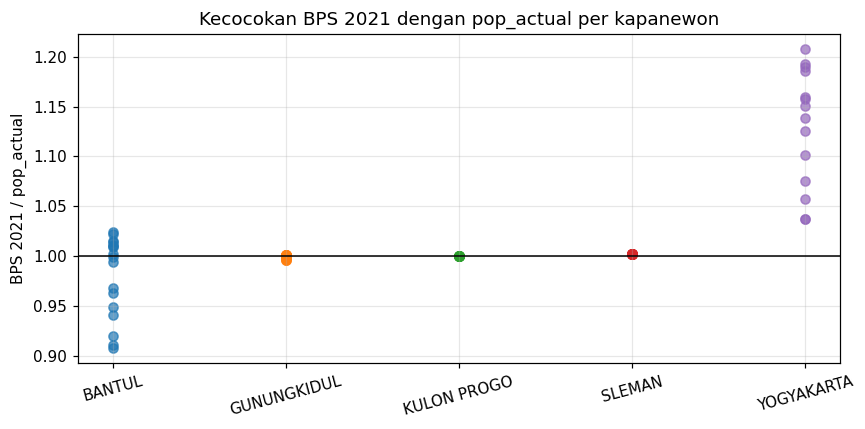

In [14]:
m = bps[bps["tahun"] == 2021][["kapanewon_code", "kab_kota", "total"]].merge(
    home[["kapanewon_code", "pop_actual", "n_users"]], on="kapanewon_code", validate="1:1")
m["rasio_bps_pop_actual"] = m["total"] / m["pop_actual"]
tabel = m.groupby("kab_kota")["rasio_bps_pop_actual"].agg(["min", "median", "max"]).round(3)
display(tabel)
fig, ax = plt.subplots(figsize=(8, 4))
for i, (k, g) in enumerate(m.groupby("kab_kota")):
    ax.scatter([i] * len(g), g["rasio_bps_pop_actual"], alpha=.7)
ax.set_xticks(range(m["kab_kota"].nunique())); ax.set_xticklabels(sorted(m["kab_kota"].unique()), rotation=15)
ax.axhline(1, color="k", lw=1); ax.set_ylabel("BPS 2021 / pop_actual")
ax.set_title("Kecocokan BPS 2021 dengan pop_actual per kapanewon")
fig.tight_layout(); fig.savefig(FIG / "03_bps_vs_pop_actual.png"); plt.show()

Sleman, Kulon Progo, dan Gunungkidul rasionya ≈ 1. Kota Yogyakarta (sampai ±1,2) dan sebagian Bantul berbeda. Angka tidak diubah, Anggota 7 yang memilih sumber.

## 8. Kualitas data OD (origin-destination)

In [15]:
od = pd.read_parquet(CLEAN / "od_home_visits_kapanewon_monthly.parquet")
q = od.groupby(od["month"].dt.strftime("%Y-%m")).agg(baris=("n_maids", "size"),
        reduced_quality=("reduced_quality", "sum"), antar_kapanewon=("is_intra", lambda s: (~s).sum()))
display(q)
print("share_of_origin:")
display(od["share_of_origin"].describe().round(3))

,baris,reduced_quality,antar_kapanewon
month,,,
2021-12,2595,0,2517
2022-01,2624,0,2546
2022-02,2653,0,2575
2022-03,1202,1202,1124
2022-04,820,820,742


share_of_origin:


count    9894.000
mean        0.088
std         0.186
min         0.001
25%         0.011
50%         0.028
75%         0.075
max         1.000
Name: share_of_origin, dtype: float64

Semua baris Mar-Apr 2022 (2.022 baris) `reduced_quality=True` dan jumlah barisnya turun (±2.600 → 1.202 dan 820). Untuk analisis OD pakai Des 2021-Feb 2022, atau beri catatan kalau Mar-Apr ikut dipakai. `share_of_origin` lengkap karena semua baris punya pembagi.

In [16]:
display(Markdown((ROOT / "docs" / "preprocessing_report.md").read_text(encoding="utf-8")))

# Laporan Preprocessing

| File | Pengecekan | Hasil |
|---|---|---|
| kapanewon_lookup | jumlah kapanewon | 78 |
| dim_kapanewon | disimpan | 78 baris x 4 kolom |
| presence_kapanewon_hourly | baris mentah | 230418 |
| presence_kapanewon_hourly | missing | 0 |
| presence_kapanewon_hourly | duplikat | 0 |
| presence_kapanewon_hourly | kode/nama tidak cocok (kapanewon_code) | 0 |
| presence_kapanewon_hourly | n_pings < n_maids | 0 |
| presence_kapanewon_hourly | slot terbit / teoritis | 230,418 / 282,672 (81.5%) |
| coverage_kapanewon_hourly | disimpan | 11,451 baris x 6 kolom |
| presence_kapanewon_hourly | disimpan | 230,418 baris x 16 kolom |
| presence_cell500m_daily | baris mentah | 183548 |
| presence_cell500m_daily | missing | 0 |
| presence_cell500m_daily | duplikat | 0 |
| presence_cell500m_daily | centroid di dalam bbox DIY | True |
| presence_cell500m_daily | disimpan | 183,548 baris x 13 kolom |
| od_origin_homes_monthly | baris mentah | 390 |
| od_origin_homes_monthly | missing | 0 |
| od_origin_homes_monthly (origin) | kode/nama tidak cocok (kapanewon_code) | 0 |
| od_home_visits_kapanewon_monthly | baris mentah | 9894 |
| od_home_visits_kapanewon_monthly | missing | 0 |
| od_home_visits_kapanewon_monthly | duplikat | 0 |
| od_home_visits_kapanewon_monthly (origin) | kode/nama tidak cocok (kapanewon_code) | 0 |
| od_home_visits_kapanewon_monthly (dest) | kode/nama tidak cocok (kapanewon_code) | 0 |
| od_home_visits_kapanewon_monthly | reduced_quality = True | 2022 |
| od_home_visits_kapanewon_monthly | baris tanpa pembagi | 0 |
| od_home_visits_kapanewon_monthly | disimpan | 9,894 baris x 14 kolom |
| od_origin_homes_monthly | disimpan | 390 baris x 8 kolom |
| home_maids_vs_population_kapanewon | baris tanpa kapanewon_code | 0 |
| home_maids_vs_population_kapanewon | selisih maks ratio | 1.11e-16 |
| home_maids_vs_population_kapanewon | disimpan | 78 baris x 8 kolom |
| validation_night_presence_kapanewon | isi kolom period | {'Dec 2021 - Apr 2022': 78, 'Dec 2021 - Jan 2022': 78} |
| validation_night_presence_kapanewon | baris tanpa kapanewon_code | 0 |
| validation_night_presence_kapanewon | missing | 0 |
| validation_night_presence_kapanewon | disimpan | 156 baris x 9 kolom |
| tier1_summary | disimpan | 2 baris x 8 kolom |
| od_summary | disimpan | 1 baris x 7 kolom |
| bps_population_kapanewon_diy_2021_2022 | baris mentah | 156 |
| bps_population_kapanewon_diy_2021_2022 | kode/nama tidak cocok (kapanewon_code) | 0 |
| bps_population_kapanewon_diy_2021_2022 | NaN laki_laki/perempuan | 36 |
| bps_population_kapanewon_diy_2021_2022 | duplikat | 0 |
| bps_population_kapanewon_diy_2021_2022 | flag_total_mismatch = True | 7 |
| bps_population_kapanewon_diy_2021_2022 | disimpan | 156 baris x 10 kolom |
